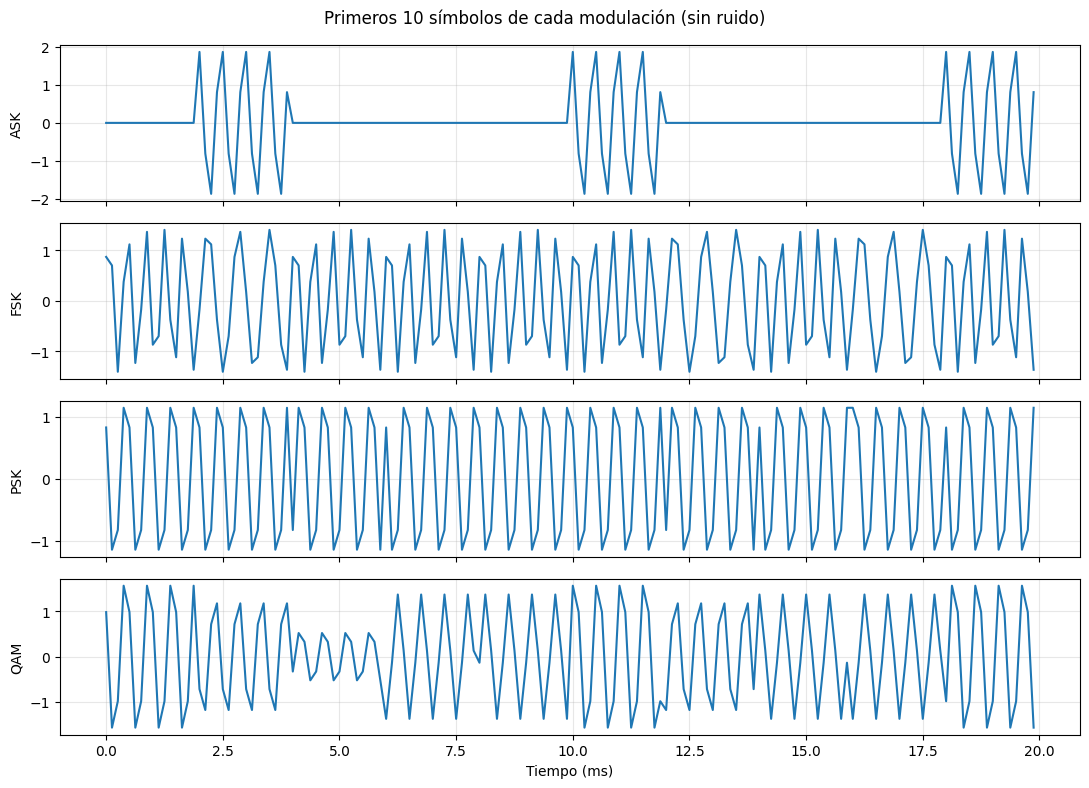

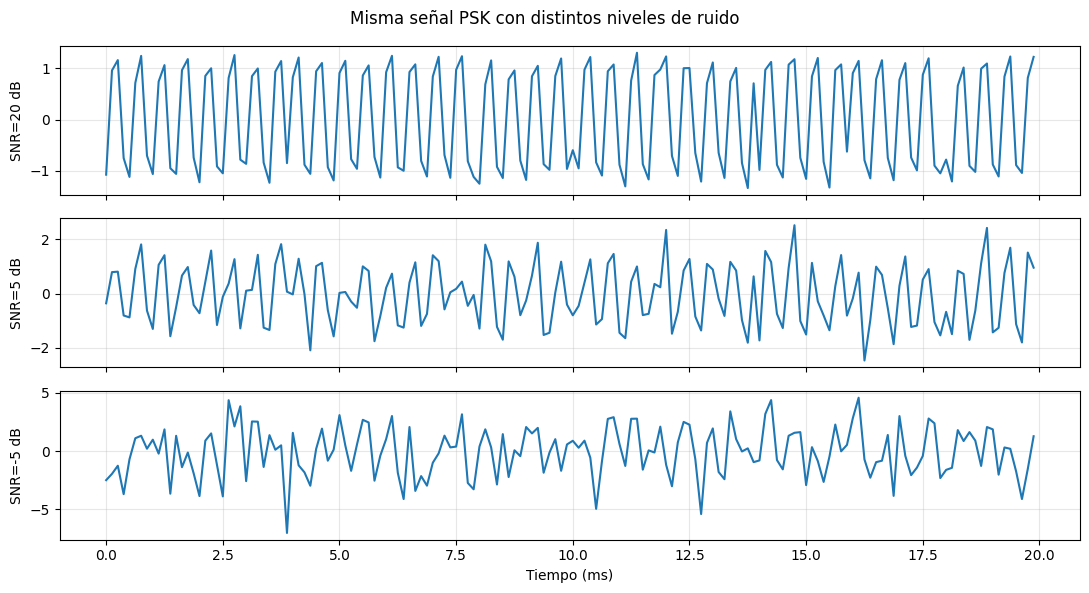

X: (4000, 1024, 1) | y: (4000,)
Entrenamiento: 3200 | Prueba: 800


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1024, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 256, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 256, 64)        │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 64, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 64, 64)         │        20,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 16, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,060 (394.77 KB)

 Trainable params: 101,060 (394.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 8s 128ms/step - accuracy: 0.4199 - loss: 1.2427 - val_accuracy: 0.6646 - val_loss: 0.9540
Epoch 2/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 90ms/step - accuracy: 0.7143 - loss: 0.7529 - val_accuracy: 0.7688 - val_loss: 0.5856
Epoch 3/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 91ms/step - accuracy: 0.8338 - loss: 0.4573 - val_accuracy: 0.8062 - val_loss: 0.4083
Epoch 4/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 5s 125ms/step - accuracy: 0.8555 - loss: 0.3687 - val_accuracy: 0.8979 - val_loss: 0.2693
Epoch 5/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 91ms/step - accuracy: 0.8754 - loss: 0.2952 - val_accuracy: 0.8583 - val_loss: 0.3511
Epoch 6/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 89ms/step - accuracy: 0.8846 - loss: 0.2729 - val_accuracy: 0.8979 - val_loss: 0.2463
Epoch 7/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 6s 145ms/step - accuracy: 0.8941 - loss: 0.2438 - val_accuracy: 0.7937 - val_loss: 0.5614
Epoch 8/30
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 92ms/step - accuracy: 0.8816 - loss: 0.2765 - val_accuracy: 0.8979 

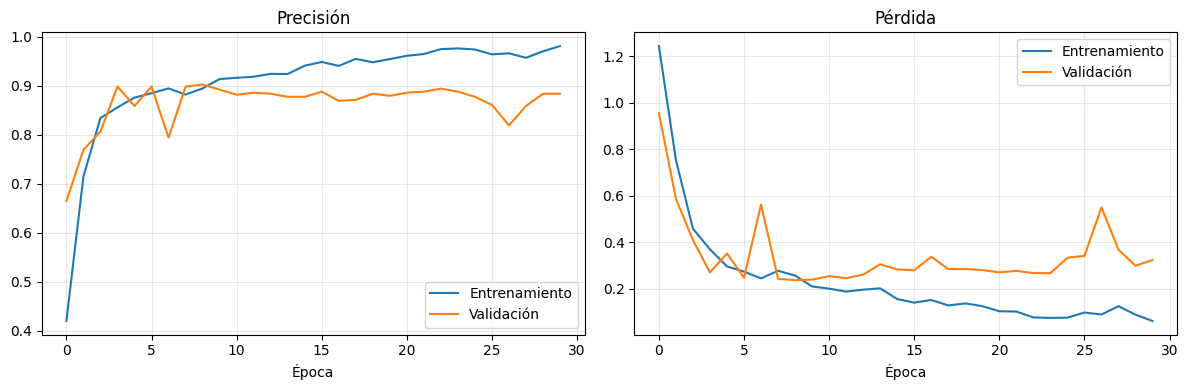


Precisión global en prueba: 87.63%


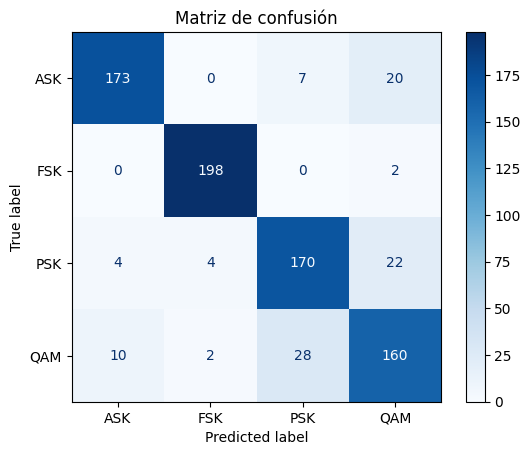

SNR -10 dB ->  48.11%
SNR  -5 dB ->  65.60%
SNR   0 dB ->  99.08%
SNR   5 dB -> 100.00%
SNR  10 dB -> 100.00%
SNR  15 dB -> 100.00%
SNR  20 dB -> 100.00%


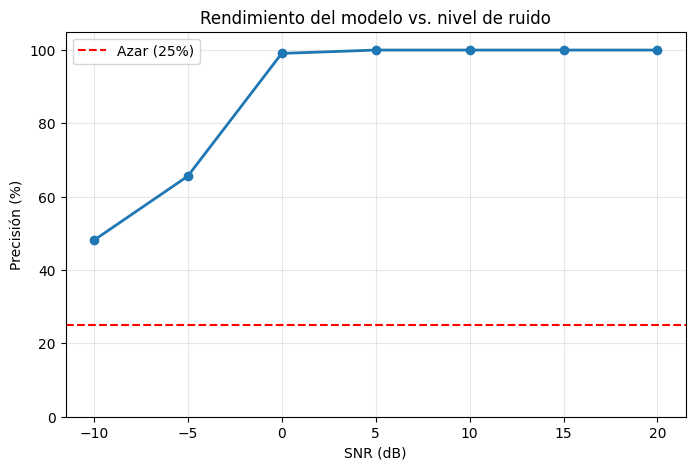

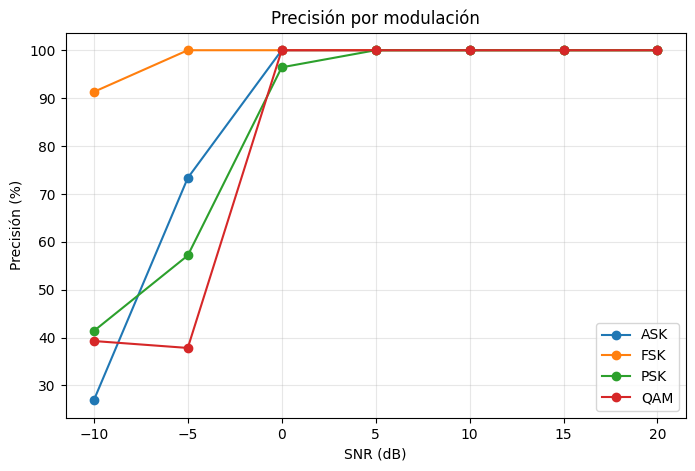


Precisión por modulación:
  ASK: 86.50%
  FSK: 99.00%
  PSK: 85.00%
  QAM: 80.00%
Modulación más difícil de clasificar: QAM


/tmp/ipykernel_1917/2240989243.py:204: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


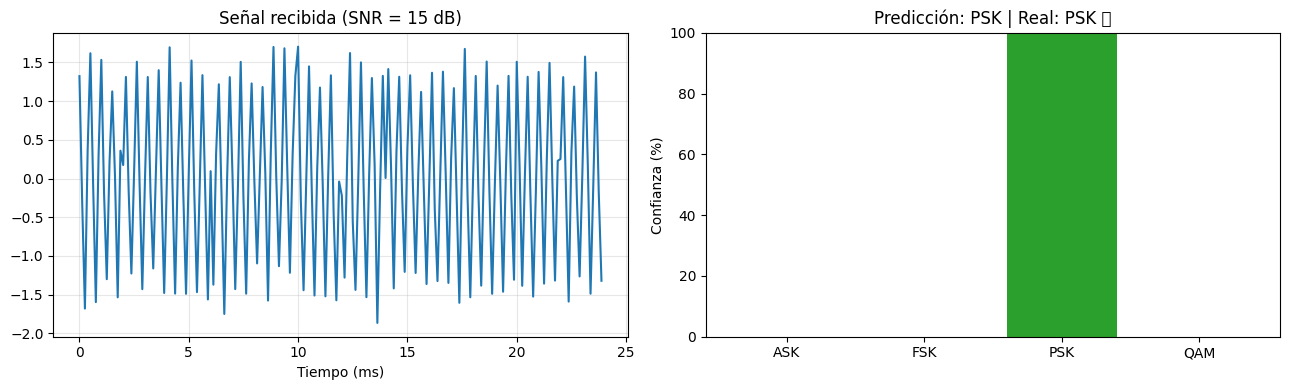

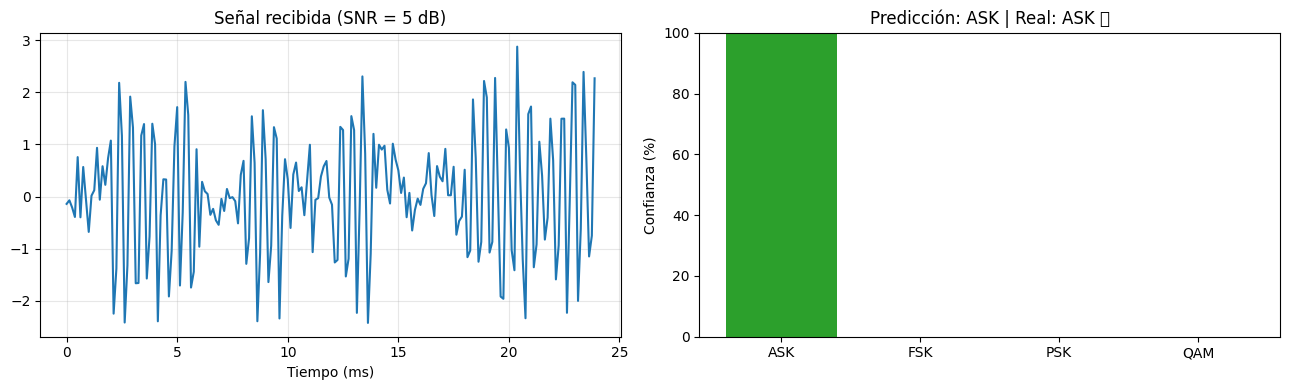

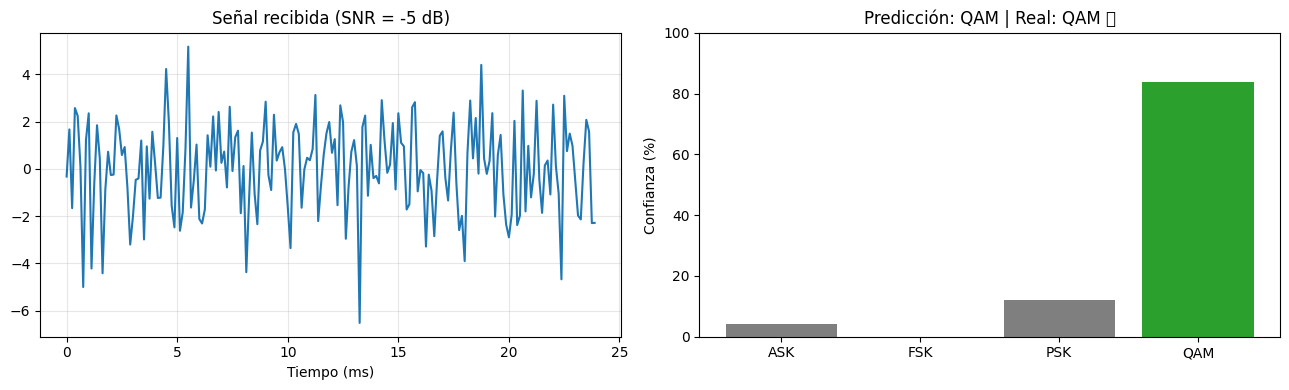

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import to_categorical

np.random.seed(42)
tf.random.set_seed(42)


fs = 8000
fc = 2000
Rs = 500
sps = fs // Rs
N_SIMBOLOS = 64
N_MUESTRAS = sps * N_SIMBOLOS
DELTA_F = 500
t = np.arange(N_MUESTRAS) / fs
CLASES = ["ASK", "FSK", "PSK", "QAM"]


def _normalizar(x):
    return x / np.sqrt(np.mean(x**2))

def generar_ask():
    bits = np.random.randint(0, 2, N_SIMBOLOS)
    amp = np.repeat(bits, sps).astype(float)
    fase = np.random.uniform(0, 2*np.pi)
    return _normalizar(amp * np.cos(2*np.pi*fc*t + fase))

def generar_fsk():
    bits = np.random.randint(0, 2, N_SIMBOLOS)
    f_inst = fc + DELTA_F * (2*np.repeat(bits, sps) - 1)
    fase_acum = 2*np.pi*np.cumsum(f_inst)/fs
    fase = np.random.uniform(0, 2*np.pi)
    return _normalizar(np.cos(fase_acum + fase))

def generar_psk():
    simbolos = np.random.randint(0, 4, N_SIMBOLOS)
    fases = np.repeat(np.pi/4 + simbolos*np.pi/2, sps)
    fase = np.random.uniform(0, 2*np.pi)
    return _normalizar(np.cos(2*np.pi*fc*t + fases + fase))

def generar_qam16():
    niveles = np.array([-3, -1, 1, 3])
    I = np.repeat(np.random.choice(niveles, N_SIMBOLOS), sps)
    Q = np.repeat(np.random.choice(niveles, N_SIMBOLOS), sps)
    fase = np.random.uniform(0, 2*np.pi)
    x = I*np.cos(2*np.pi*fc*t + fase) - Q*np.sin(2*np.pi*fc*t + fase)
    return _normalizar(x)

GENERADORES = [generar_ask, generar_fsk, generar_psk, generar_qam16]


fig, axs = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, nombre, gen in zip(axs, CLASES, GENERADORES):
    ax.plot(t[:sps*10]*1000, gen()[:sps*10])
    ax.set_ylabel(nombre); ax.grid(alpha=0.3)
axs[-1].set_xlabel("Tiempo (ms)")
plt.suptitle("Primeros 10 símbolos de cada modulación (sin ruido)")
plt.tight_layout(); plt.show()


def agregar_awgn(x, snr_db):
    potencia_senal = np.mean(x**2)
    potencia_ruido = potencia_senal / (10**(snr_db/10))
    return x + np.random.normal(0, np.sqrt(potencia_ruido), len(x))


base = generar_psk()
fig, axs = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
for ax, snr in zip(axs, [20, 5, -5]):
    ax.plot(t[:sps*10]*1000, agregar_awgn(base, snr)[:sps*10])
    ax.set_ylabel(f"SNR={snr} dB"); ax.grid(alpha=0.3)
axs[-1].set_xlabel("Tiempo (ms)")
plt.suptitle("Misma señal PSK con distintos niveles de ruido")
plt.tight_layout(); plt.show()

MUESTRAS_POR_CLASE = 1000
SNR_LISTA = np.arange(-10, 21, 5)

X, y, snrs = [], [], []
for etiqueta, gen in enumerate(GENERADORES):
    for _ in range(MUESTRAS_POR_CLASE):
        snr = np.random.choice(SNR_LISTA)
        X.append(agregar_awgn(gen(), snr))
        y.append(etiqueta)
        snrs.append(snr)

X = np.array(X, dtype=np.float32)[..., np.newaxis]
y = np.array(y)
snrs = np.array(snrs)
print("X:", X.shape, "| y:", y.shape)
np.savez_compressed("dataset_modulaciones.npz", X=X, y=y, snrs=snrs)

X_train, X_test, y_train, y_test, snr_train, snr_test = train_test_split(
    X, y, snrs, test_size=0.20, stratify=y, random_state=42)

y_train_cat = to_categorical(y_train, 4)
y_test_cat  = to_categorical(y_test, 4)
print("Entrenamiento:", X_train.shape[0], "| Prueba:", X_test.shape[0])


modelo = keras.Sequential([
    layers.Input(shape=(N_MUESTRAS, 1)),
    layers.Conv1D(32, 7, activation="relu", padding="same"),
    layers.MaxPooling1D(4),
    layers.Conv1D(64, 7, activation="relu", padding="same"),
    layers.MaxPooling1D(4),
    layers.Conv1D(64, 5, activation="relu", padding="same"),
    layers.MaxPooling1D(4),
    layers.Flatten(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(4, activation="softmax"),
])
modelo.summary()


modelo.compile(optimizer="adam",
               loss="categorical_crossentropy",
               metrics=["accuracy"])


historial = modelo.fit(X_train, y_train_cat,
                       epochs=30, batch_size=64,
                       validation_split=0.15, verbose=1)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(historial.history["accuracy"], label="Entrenamiento")
a1.plot(historial.history["val_accuracy"], label="Validación")
a1.set_title("Precisión"); a1.set_xlabel("Época"); a1.legend(); a1.grid(alpha=0.3)
a2.plot(historial.history["loss"], label="Entrenamiento")
a2.plot(historial.history["val_loss"], label="Validación")
a2.set_title("Pérdida"); a2.set_xlabel("Época"); a2.legend(); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()

modelo.save("detective_de_senales.keras")

y_prob = modelo.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

loss, acc = modelo.evaluate(X_test, y_test_cat, verbose=0)
print(f"\nPrecisión global en prueba: {acc*100:.2f}%")

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(cmap="Blues", values_format="d")
plt.title("Matriz de confusión")
plt.show()

precision_por_snr = []
for snr in SNR_LISTA:
    mascara = snr_test == snr
    p = np.mean(y_pred[mascara] == y_test[mascara]) * 100
    precision_por_snr.append(p)
    print(f"SNR {snr:>3} dB -> {p:6.2f}%")

plt.figure(figsize=(8, 5))
plt.plot(SNR_LISTA, precision_por_snr, "o-", linewidth=2)
plt.axhline(25, color="red", linestyle="--", label="Azar (25%)")
plt.xlabel("SNR (dB)"); plt.ylabel("Precisión (%)")
plt.title("Rendimiento del modelo vs. nivel de ruido")
plt.ylim(0, 105); plt.grid(alpha=0.3); plt.legend()
plt.show()


plt.figure(figsize=(8, 5))
for i, nombre in enumerate(CLASES):
    acc_i = []
    for snr in SNR_LISTA:
        m = (snr_test == snr) & (y_test == i)
        acc_i.append(np.mean(y_pred[m] == y_test[m]) * 100)
    plt.plot(SNR_LISTA, acc_i, "o-", label=nombre)
plt.xlabel("SNR (dB)"); plt.ylabel("Precisión (%)")
plt.title("Precisión por modulación"); plt.grid(alpha=0.3); plt.legend()
plt.show()


precision_clase = cm.diagonal() / cm.sum(axis=1) * 100
print("\nPrecisión por modulación:")
for nombre, p in zip(CLASES, precision_clase):
    print(f"  {nombre}: {p:.2f}%")
print("Modulación más difícil de clasificar:", CLASES[int(np.argmin(precision_clase))])


def demo(snr_db=10):
    idx = np.random.randint(4)
    senal = agregar_awgn(GENERADORES[idx](), snr_db)
    prob = modelo.predict(senal[np.newaxis, :, np.newaxis], verbose=0)[0]
    pred = int(np.argmax(prob))

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    a1.plot(t[:sps*12]*1000, senal[:sps*12])
    a1.set_title(f"Señal recibida (SNR = {snr_db} dB)")
    a1.set_xlabel("Tiempo (ms)"); a1.grid(alpha=0.3)
    colores = ["tab:green" if i == pred else "tab:gray" for i in range(4)]
    a2.bar(CLASES, prob*100, color=colores)
    a2.set_ylabel("Confianza (%)"); a2.set_ylim(0, 100)
    a2.set_title(f"Predicción: {CLASES[pred]} | Real: {CLASES[idx]} "
                 f"{'✅' if pred == idx else '❌'}")
    plt.tight_layout(); plt.show()

for snr in [15, 5, -5]:
    demo(snr)